ARIMAX

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                18412
Model:               SARIMAX(0, 1, 0)   Log Likelihood              -89309.365
Date:                Fri, 26 Dec 2025   AIC                         178642.729
Time:                        14:12:23   BIC                         178736.577
Sample:                    01-01-2022   HQIC                        178673.557
                         - 02-07-2024                                         
Covariance Type:                  opg                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
PM10                   2.6795      0.028     97.411      0.000       2.626       2.733
SO2                    0.1825      0.035      5.209      0.000       0.114       0.251
CO                  

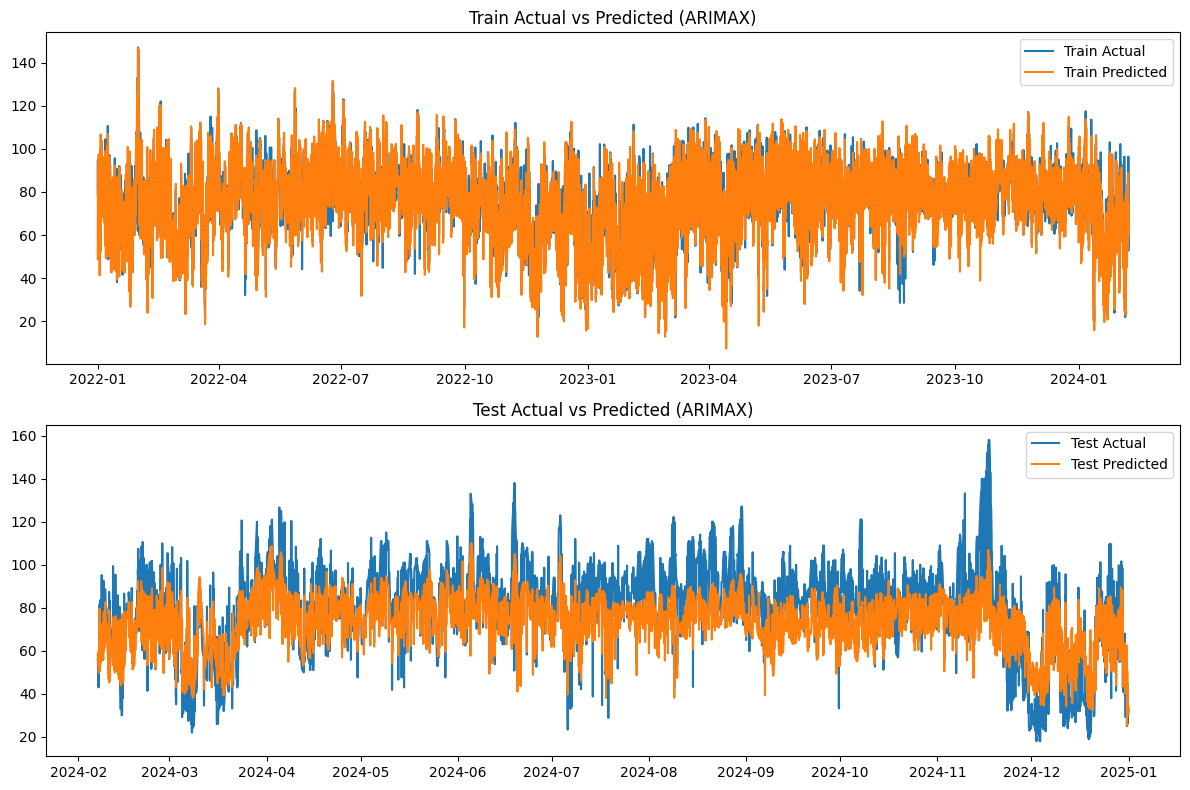

In [ ]:
import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import boxcox
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# =====================================================
# 1. LOAD DATA
# =====================================================
df_path = "/content/drive/MyDrive/Data/Data Aqi Pollutant dan Meteorologi Kebon Jeruk.xlsx"
df = pd.read_excel(df_path, parse_dates=['datetime'], index_col='datetime')

y_raw = df['PM2.5']
X = df[['PM10','SO2','CO','O3','NO2','Suhu Udara','Radiasi Matahari','Suhu Titik Embun',
        'Curah Hujan','Kelembaban Relatif','Kecepatan Angin']]

# =====================================================
# 2. BOX-COX TRANSFORMATION
# =====================================================
y_pos = y_raw + 1
y_boxcox, lmbda = boxcox(y_pos)
y_boxcox_series = pd.Series(y_boxcox, index=df.index)

def inv_boxcox(y, l):
    return np.exp(np.log(l*y + 1)/l) - 1 if l != 0 else np.exp(y) - 1

# =====================================================
# 3. TRAIN TEST SPLIT
# =====================================================
train_size = int(len(df) * 0.7)

y_train_bc = y_boxcox_series.iloc[:train_size]
y_test_bc  = y_boxcox_series.iloc[train_size:]

X_train = X.iloc[:train_size]
X_test  = X.iloc[train_size:]

y_train_real = y_raw.iloc[:train_size]
y_test_real  = y_raw.iloc[train_size:]

# =====================================================
# 4. SARIMAX / ARIMAX MODELING
# =====================================================
order = (0, 1, 0)

model = SARIMAX(y_train_bc, exog=X_train, order=order,
                enforce_stationarity=False, enforce_invertibility=False)

result = model.fit()
print(result.summary())

# =====================================================
# 5. PREDIKSI TRAIN & TEST
# =====================================================
pred_train_bc = result.predict(start=y_train_bc.index[0],
                               end=y_train_bc.index[-1],
                               exog=X_train)

pred_test_bc = result.predict(start=y_test_bc.index[0],
                              end=y_test_bc.index[-1],
                              exog=X_test)

# inverse Box-Cox ke skala asli
pred_train = inv_boxcox(pred_train_bc, lmbda)
pred_test  = inv_boxcox(pred_test_bc, lmbda)

# =====================================================
# 6. EVALUASI MODEL
# =====================================================
def print_metrics(true, pred, label=""):
    print(f"\n=== {label} Accuracy ===")
    print("MAE :", mean_absolute_error(true, pred))
    print("RMSE:", np.sqrt(mean_squared_error(true, pred)))
    print("R2  :", r2_score(true, pred))

print_metrics(y_train_real, pred_train, "Train")
print_metrics(y_test_real, pred_test, "Test")

# =====================================================
# 7. PLOT ACTUAL vs PREDICTED
# =====================================================
fig, ax = plt.subplots(2, 1, figsize=(12, 8))

ax[0].plot(y_train_real.index, y_train_real, label='Train Actual')
ax[0].plot(y_train_real.index, pred_train, label='Train Predicted')
ax[0].set_title("Train Actual vs Predicted (ARIMAX)")
ax[0].legend()

ax[1].plot(y_test_real.index, y_test_real, label='Test Actual')
ax[1].plot(y_test_real.index, pred_test, label='Test Predicted')
ax[1].set_title("Test Actual vs Predicted (ARIMAX)")
ax[1].legend()

plt.tight_layout()
plt.show()

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                18412
Model:               SARIMAX(0, 1, 1)   Log Likelihood              -86794.302
Date:                Sat, 27 Dec 2025   AIC                         173614.604
Time:                        07:48:19   BIC                         173716.272
Sample:                    01-01-2022   HQIC                        173648.001
                         - 02-07-2024                                         
Covariance Type:                  opg                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
PM10                   2.8110      0.027    102.813      0.000       2.757       2.865
SO2                    0.1650      0.036      4.593      0.000       0.095       0.235
CO                  

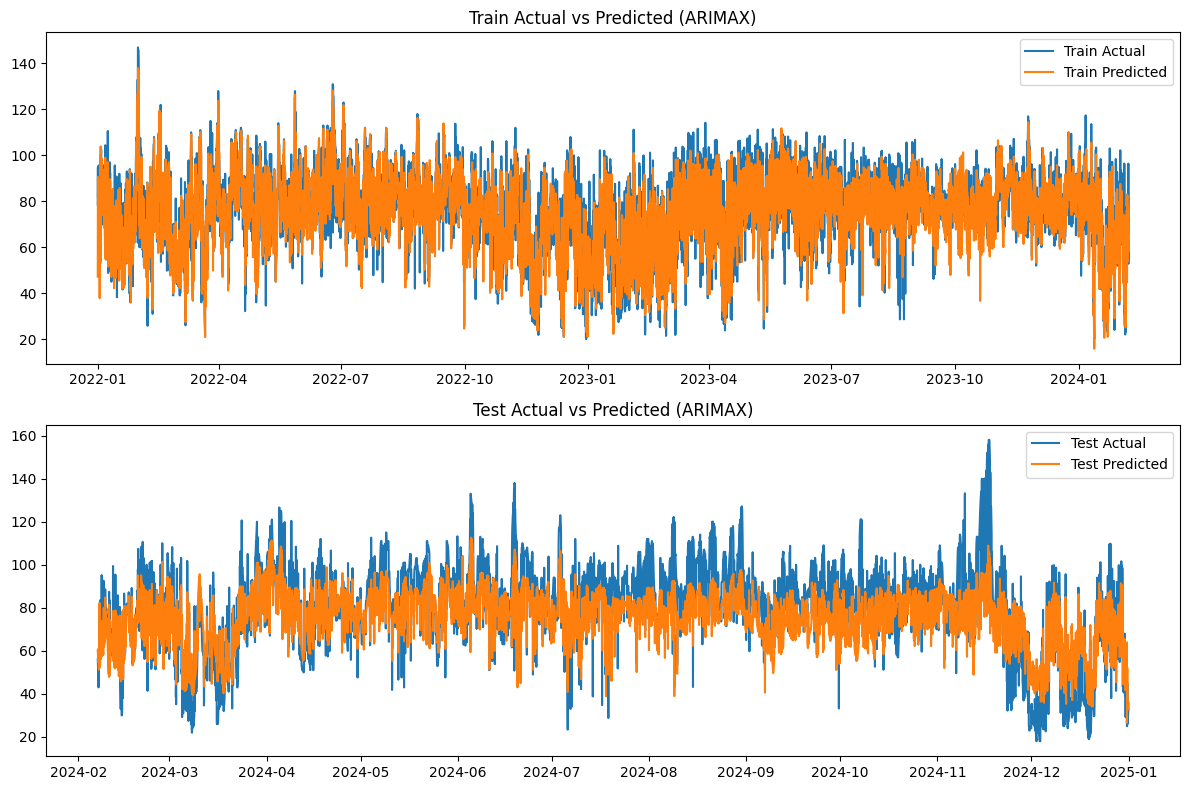

In [ ]:
import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import boxcox
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# =====================================================
# 1. LOAD DATA
# =====================================================
df_path = "/content/drive/MyDrive/Data/Data Aqi Pollutant dan Meteorologi Kebon Jeruk.xlsx"
df = pd.read_excel(df_path, parse_dates=['datetime'], index_col='datetime')

y_raw = df['PM2.5']
X = df[['PM10','SO2','CO','O3','NO2','Suhu Udara','Radiasi Matahari','Suhu Titik Embun',
        'Curah Hujan','Kelembaban Relatif','Kecepatan Angin']]

# =====================================================
# 2. BOX-COX TRANSFORMATION
# =====================================================
y_pos = y_raw + 1
y_boxcox, lmbda = boxcox(y_pos)
y_boxcox_series = pd.Series(y_boxcox, index=df.index)

def inv_boxcox(y, l):
    return np.exp(np.log(l*y + 1)/l) - 1 if l != 0 else np.exp(y) - 1

# =====================================================
# 3. TRAIN TEST SPLIT
# =====================================================
train_size = int(len(df) * 0.7)

y_train_bc = y_boxcox_series.iloc[:train_size]
y_test_bc  = y_boxcox_series.iloc[train_size:]

X_train = X.iloc[:train_size]
X_test  = X.iloc[train_size:]

y_train_real = y_raw.iloc[:train_size]
y_test_real  = y_raw.iloc[train_size:]

# =====================================================
# 4. SARIMAX / ARIMAX MODELING
# =====================================================
order = (0, 1, 1)

model = SARIMAX(y_train_bc, exog=X_train, order=order,
                enforce_stationarity=False, enforce_invertibility=False)

result = model.fit()
print(result.summary())

# =====================================================
# 5. PREDIKSI TRAIN & TEST
# =====================================================
pred_train_bc = result.predict(start=y_train_bc.index[0],
                               end=y_train_bc.index[-1],
                               exog=X_train)

pred_test_bc = result.predict(start=y_test_bc.index[0],
                              end=y_test_bc.index[-1],
                              exog=X_test)

# inverse Box-Cox ke skala asli
pred_train = inv_boxcox(pred_train_bc, lmbda)
pred_test  = inv_boxcox(pred_test_bc, lmbda)

# =====================================================
# 6. EVALUASI MODEL
# =====================================================
def print_metrics(true, pred, label=""):
    print(f"\n=== {label} Accuracy ===")
    print("MAE :", mean_absolute_error(true, pred))
    print("RMSE:", np.sqrt(mean_squared_error(true, pred)))
    print("R2  :", r2_score(true, pred))

print_metrics(y_train_real, pred_train, "Train")
print_metrics(y_test_real, pred_test, "Test")

# =====================================================
# 7. PLOT ACTUAL vs PREDICTED
# =====================================================
fig, ax = plt.subplots(2, 1, figsize=(12, 8))

ax[0].plot(y_train_real.index, y_train_real, label='Train Actual')
ax[0].plot(y_train_real.index, pred_train, label='Train Predicted')
ax[0].set_title("Train Actual vs Predicted (ARIMAX)")
ax[0].legend()

ax[1].plot(y_test_real.index, y_test_real, label='Test Actual')
ax[1].plot(y_test_real.index, pred_test, label='Test Predicted')
ax[1].set_title("Test Actual vs Predicted (ARIMAX)")
ax[1].legend()

plt.tight_layout()
plt.show()

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                18412
Model:               SARIMAX(0, 1, 2)   Log Likelihood              -86581.603
Date:                Sat, 27 Dec 2025   AIC                         173191.206
Time:                        07:49:21   BIC                         173300.694
Sample:                    01-01-2022   HQIC                        173227.171
                         - 02-07-2024                                         
Covariance Type:                  opg                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
PM10                   2.7967      0.028    100.681      0.000       2.742       2.851
SO2                    0.1927      0.036      5.335      0.000       0.122       0.263
CO                  

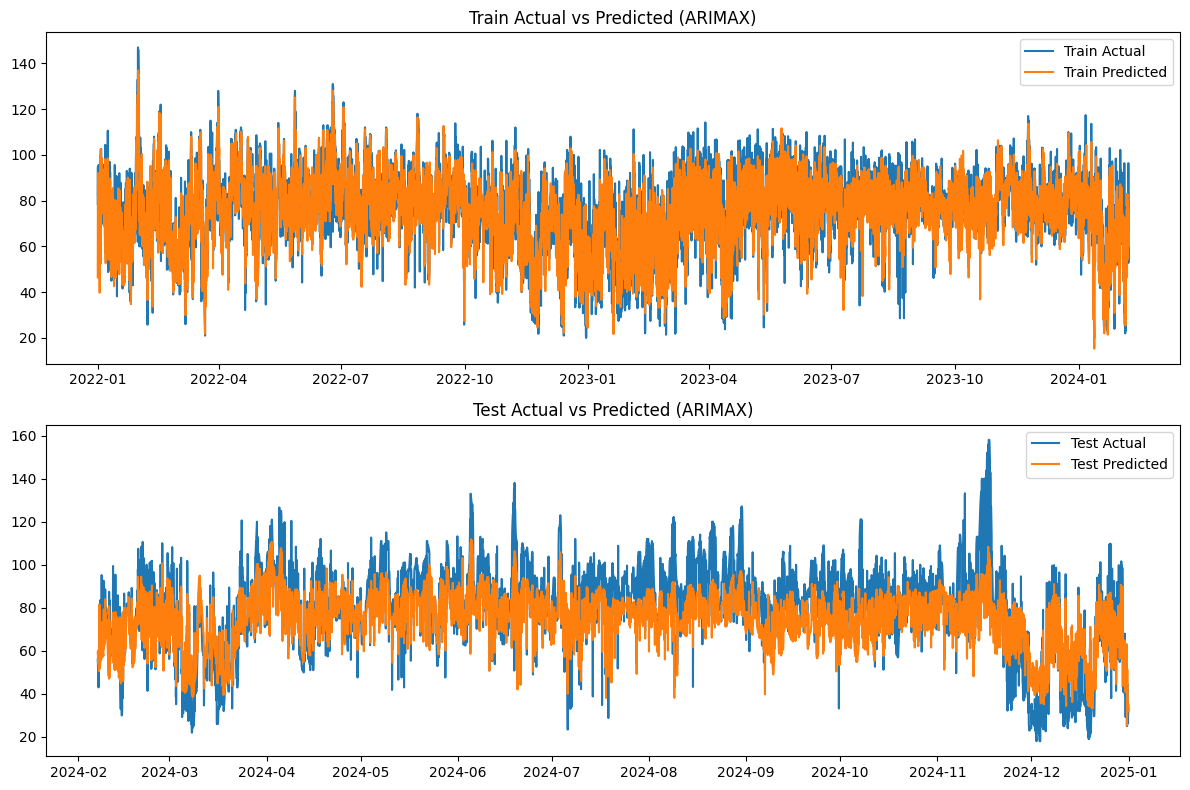

In [ ]:
import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import boxcox
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# =====================================================
# 1. LOAD DATA
# =====================================================
df_path = "/content/drive/MyDrive/Data/Data Aqi Pollutant dan Meteorologi Kebon Jeruk.xlsx"
df = pd.read_excel(df_path, parse_dates=['datetime'], index_col='datetime')

y_raw = df['PM2.5']
X = df[['PM10','SO2','CO','O3','NO2','Suhu Udara','Radiasi Matahari','Suhu Titik Embun',
        'Curah Hujan','Kelembaban Relatif','Kecepatan Angin']]

# =====================================================
# 2. BOX-COX TRANSFORMATION
# =====================================================
y_pos = y_raw + 1
y_boxcox, lmbda = boxcox(y_pos)
y_boxcox_series = pd.Series(y_boxcox, index=df.index)

def inv_boxcox(y, l):
    return np.exp(np.log(l*y + 1)/l) - 1 if l != 0 else np.exp(y) - 1

# =====================================================
# 3. TRAIN TEST SPLIT
# =====================================================
train_size = int(len(df) * 0.7)

y_train_bc = y_boxcox_series.iloc[:train_size]
y_test_bc  = y_boxcox_series.iloc[train_size:]

X_train = X.iloc[:train_size]
X_test  = X.iloc[train_size:]

y_train_real = y_raw.iloc[:train_size]
y_test_real  = y_raw.iloc[train_size:]

# =====================================================
# 4. SARIMAX / ARIMAX MODELING
# =====================================================
order = (0, 1, 2)

model = SARIMAX(y_train_bc, exog=X_train, order=order,
                enforce_stationarity=False, enforce_invertibility=False)

result = model.fit()
print(result.summary())

# =====================================================
# 5. PREDIKSI TRAIN & TEST
# =====================================================
pred_train_bc = result.predict(start=y_train_bc.index[0],
                               end=y_train_bc.index[-1],
                               exog=X_train)

pred_test_bc = result.predict(start=y_test_bc.index[0],
                              end=y_test_bc.index[-1],
                              exog=X_test)

# inverse Box-Cox ke skala asli
pred_train = inv_boxcox(pred_train_bc, lmbda)
pred_test  = inv_boxcox(pred_test_bc, lmbda)

# =====================================================
# 6. EVALUASI MODEL
# =====================================================
def print_metrics(true, pred, label=""):
    print(f"\n=== {label} Accuracy ===")
    print("MAE :", mean_absolute_error(true, pred))
    print("RMSE:", np.sqrt(mean_squared_error(true, pred)))
    print("R2  :", r2_score(true, pred))

print_metrics(y_train_real, pred_train, "Train")
print_metrics(y_test_real, pred_test, "Test")

# =====================================================
# 7. PLOT ACTUAL vs PREDICTED
# =====================================================
fig, ax = plt.subplots(2, 1, figsize=(12, 8))

ax[0].plot(y_train_real.index, y_train_real, label='Train Actual')
ax[0].plot(y_train_real.index, pred_train, label='Train Predicted')
ax[0].set_title("Train Actual vs Predicted (ARIMAX)")
ax[0].legend()

ax[1].plot(y_test_real.index, y_test_real, label='Test Actual')
ax[1].plot(y_test_real.index, pred_test, label='Test Predicted')
ax[1].set_title("Test Actual vs Predicted (ARIMAX)")
ax[1].legend()

plt.tight_layout()
plt.show()

Drop Variabel Eksogen Radiasi Matahari

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                18412
Model:               SARIMAX(0, 1, 2)   Log Likelihood              -86578.993
Date:                Fri, 30 Jan 2026   AIC                         173183.986
Time:                        16:38:24   BIC                         173285.653
Sample:                    01-01-2022   HQIC                        173217.382
                         - 02-07-2024                                         
Covariance Type:                  opg                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
PM10                   2.7926      0.028    101.098      0.000       2.738       2.847
SO2                    0.1586      0.036      4.414      0.000       0.088       0.229
CO                  

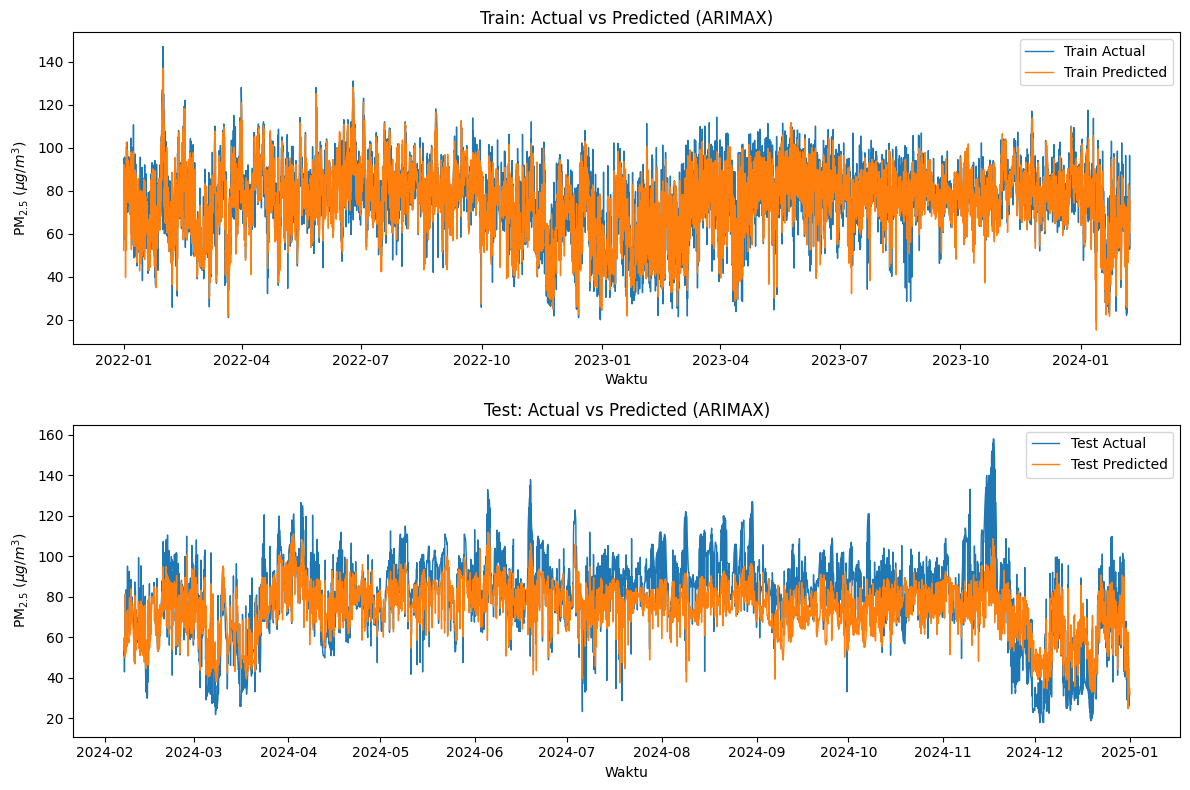

In [3]:
import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import boxcox
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# =====================================================
# 1. LOAD DATA
# =====================================================
df_path = "/content/drive/MyDrive/Data/Data Aqi Pollutant dan Meteorologi Kebon Jeruk.xlsx"
df = pd.read_excel(df_path, parse_dates=['datetime'], index_col='datetime')

y_raw = df['PM2.5']
X = df[['PM10','SO2','CO','O3','NO2','Suhu Udara','Suhu Titik Embun','Curah Hujan','Kelembaban Relatif','Kecepatan Angin']]

# =====================================================
# 2. BOX-COX TRANSFORMATION
# =====================================================
y_pos = y_raw + 1
y_boxcox, lmbda = boxcox(y_pos)
y_boxcox_series = pd.Series(y_boxcox, index=df.index)

def inv_boxcox(y, l):
    return np.exp(np.log(l*y + 1)/l) - 1 if l != 0 else np.exp(y) - 1

# =====================================================
# 3. TRAIN TEST SPLIT
# =====================================================
train_size = int(len(df) * 0.7)

y_train_bc = y_boxcox_series.iloc[:train_size]
y_test_bc  = y_boxcox_series.iloc[train_size:]

X_train = X.iloc[:train_size]
X_test  = X.iloc[train_size:]

y_train_real = y_raw.iloc[:train_size]
y_test_real  = y_raw.iloc[train_size:]

# =====================================================
# 4. SARIMAX / ARIMAX MODELING
# =====================================================
order = (0, 1, 2)

model = SARIMAX(y_train_bc, exog=X_train, order=order,
                enforce_stationarity=False, enforce_invertibility=False)

result = model.fit()
print(result.summary())

# =====================================================
# 5. PREDIKSI TRAIN & TEST
# =====================================================
pred_train_bc = result.predict(start=y_train_bc.index[0],
                               end=y_train_bc.index[-1],
                               exog=X_train)

pred_test_bc = result.predict(start=y_test_bc.index[0],
                              end=y_test_bc.index[-1],
                              exog=X_test)

# inverse Box-Cox ke skala asli
pred_train = inv_boxcox(pred_train_bc, lmbda)
pred_test  = inv_boxcox(pred_test_bc, lmbda)

# =====================================================
# 6. EVALUASI MODEL
# =====================================================
def print_metrics(true, pred, label=""):
    print(f"\n=== {label} Accuracy ===")
    print("MAE :", mean_absolute_error(true, pred))
    print("RMSE:", np.sqrt(mean_squared_error(true, pred)))
    print("R2  :", r2_score(true, pred))

print_metrics(y_train_real, pred_train, "Train")
print_metrics(y_test_real, pred_test, "Test")

# =====================================================
# 7. PLOT ACTUAL vs PREDICTED
# =====================================================
# =========================
# 5. Plot hasil
# =========================
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=False)

# --- Plot Train ---
ax[0].plot(y_train_real.index, y_train_real,
           label='Train Actual', linewidth=1)
ax[0].plot(pred_train.index, pred_train,
           label='Train Predicted', linewidth=1)
ax[0].set_title('Train: Actual vs Predicted (ARIMAX)', fontsize=12)
ax[0].legend()

# --- Plot Test ---
ax[1].plot(y_test_real.index, y_test_real,
           label='Test Actual', linewidth=1)
ax[1].plot(pred_test.index, pred_test,
           label='Test Predicted', linewidth=1)
ax[1].set_title('Test: Actual vs Predicted (ARIMAX)', fontsize=12)
ax[1].legend()

ax[0].set_ylabel(r'PM$_{2.5}$ ($\mu g/m^3$)')
ax[1].set_ylabel(r'PM$_{2.5}$ ($\mu g/m^3$)')
ax[0].set_xlabel('Waktu')
ax[1].set_xlabel('Waktu')

plt.tight_layout()
plt.show()

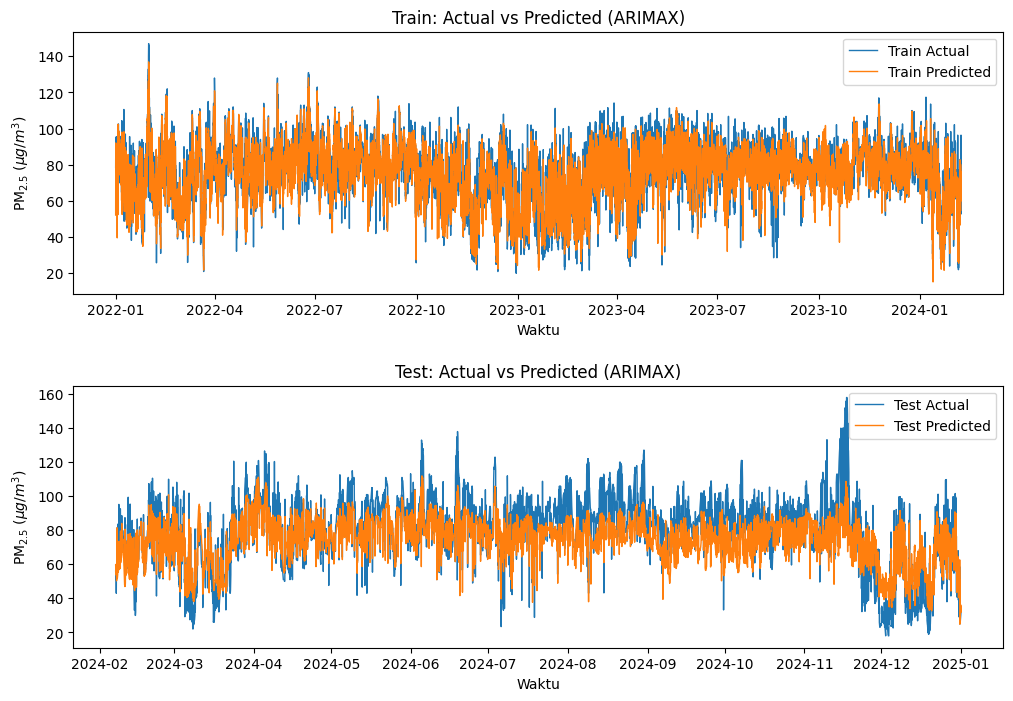

Gambar BERHASIL disimpan di:
/content/drive/MyDrive/Model ARIMAX 2/Kebun Jeruk/Gambar/ARIMAX_Train_Test.jpeg


In [4]:
import os
# =========================
# 6. Plot + SIMPAN + TAMPIL
# =========================
output_dir = "/content/drive/MyDrive/Model ARIMAX 2/Kebun Jeruk/Gambar"
os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(output_dir, "ARIMAX_Train_Test.jpeg")

fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=False)

# --- Plot Train ---
ax[0].plot(y_train_real.index, y_train_real,
           label='Train Actual', linewidth=1)
ax[0].plot(pred_train.index, pred_train,
           label='Train Predicted', linewidth=1)
ax[0].set_title('Train: Actual vs Predicted (ARIMAX)', fontsize=12)
ax[0].legend()

# --- Plot Test ---
ax[1].plot(y_test_real.index, y_test_real,
           label='Test Actual', linewidth=1)
ax[1].plot(pred_test.index, pred_test,
           label='Test Predicted', linewidth=1)
ax[1].set_title('Test: Actual vs Predicted (ARIMAX)', fontsize=12)
ax[1].legend()

ax[0].set_ylabel(r'PM$_{2.5}$ ($\mu g/m^3$)')
ax[1].set_ylabel(r'PM$_{2.5}$ ($\mu g/m^3$)')
ax[0].set_xlabel('Waktu')
ax[1].set_xlabel('Waktu')

plt.subplots_adjust(hspace=0.35)
plt.savefig(output_path, dpi=600, bbox_inches="tight")
plt.show()
plt.close()

print("Gambar BERHASIL disimpan di:")
print(output_path)

Hybrid ARIMAX-SVR

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                18412
Model:               SARIMAX(0, 1, 2)   Log Likelihood              -86578.993
Date:                Sun, 04 Jan 2026   AIC                         173183.986
Time:                        09:09:15   BIC                         173285.653
Sample:                    01-01-2022   HQIC                        173217.382
                         - 02-07-2024                                         
Covariance Type:                  opg                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
PM10                   2.7926      0.028    101.098      0.000       2.738       2.847
SO2                    0.1586      0.036      4.414      0.000       0.088       0.229
CO                  

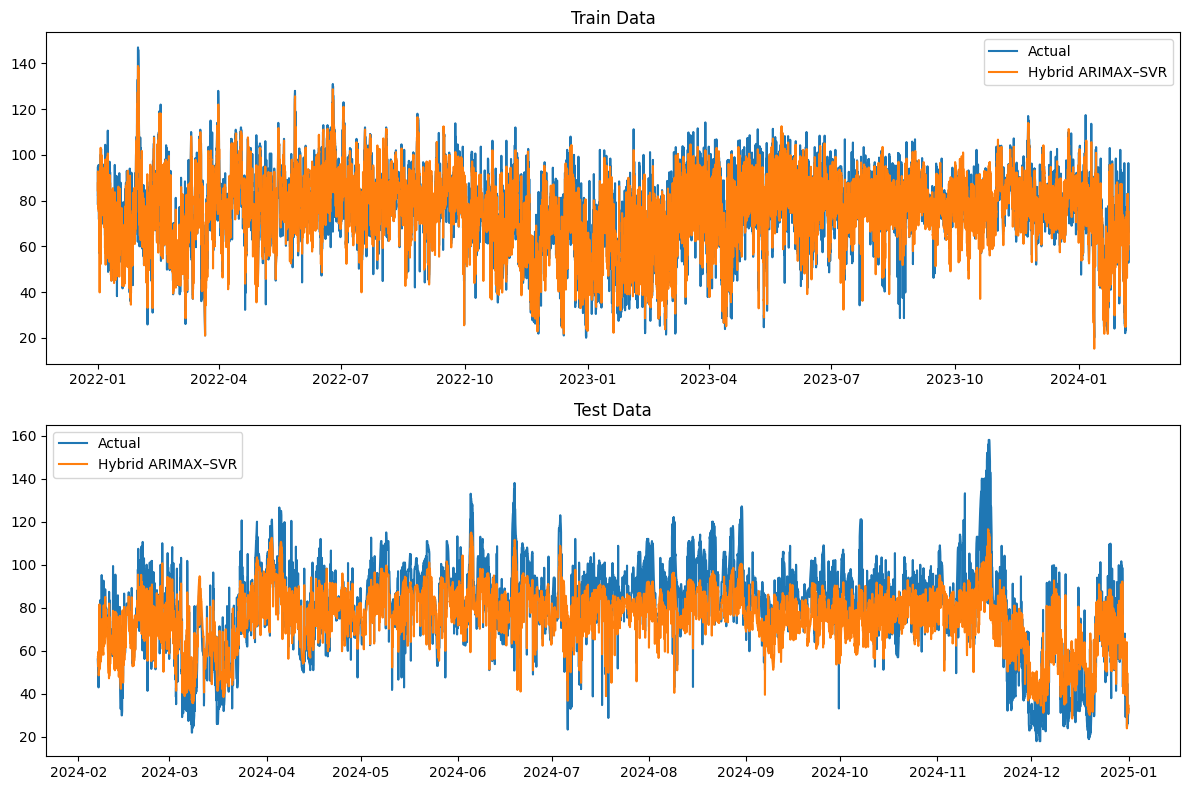

In [ ]:
import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
from scipy.stats import boxcox
from scipy.special import inv_boxcox
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# =====================================================
# 1. LOAD DATA
# =====================================================
df_path = "/content/drive/MyDrive/Data/Data Aqi Pollutant dan Meteorologi Kebon Jeruk.xlsx"
df = pd.read_excel(df_path, parse_dates=['datetime'], index_col='datetime')

y_raw = df['PM2.5']
X = df[['PM10','SO2','CO','O3','NO2',
        'Suhu Udara','Suhu Titik Embun','Curah Hujan',
        'Kelembaban Relatif','Kecepatan Angin']]

# =====================================================
# 2. BOX-COX TRANSFORMATION
# =====================================================
y_pos = y_raw + 1
y_boxcox, lmbda = boxcox(y_pos)
y_bc = pd.Series(y_boxcox, index=y_raw.index)

# =====================================================
# 3. TRAIN TEST SPLIT
# =====================================================
train_size = int(len(df) * 0.7)

y_train_bc = y_bc.iloc[:train_size]
y_test_bc  = y_bc.iloc[train_size:]

X_train = X.iloc[:train_size]
X_test  = X.iloc[train_size:]

y_train_real = y_raw.iloc[:train_size]
y_test_real  = y_raw.iloc[train_size:]

# =====================================================
# 4. ARIMAX MODEL
# =====================================================
order = (0, 1, 2)

model = SARIMAX(
    y_train_bc,
    exog=X_train,
    order=order,
    enforce_stationarity=False,
    enforce_invertibility=False
)

result = model.fit()
print(result.summary())

# =====================================================
# 5. PREDIKSI ARIMAX + INVERSE BOXCOX
# =====================================================
pred_train_bc = result.get_prediction(
    start=y_train_bc.index[0],
    end=y_train_bc.index[-1],
    exog=X_train
).predicted_mean

pred_test_bc = result.get_prediction(
    start=y_test_bc.index[0],
    end=y_test_bc.index[-1],
    exog=X_test
).predicted_mean

arimax_train = inv_boxcox(pred_train_bc, lmbda) - 1
arimax_test  = inv_boxcox(pred_test_bc,  lmbda) - 1

# =====================================================
# 6. HITUNG RESIDUAL ARIMAX
# =====================================================
residual_train = y_train_real - arimax_train
residual_test  = y_test_real  - arimax_test

# =====================================================
# 7. BUAT LAG RESIDUAL
# =====================================================
def create_lagged_residual(residual, n_lags=1):
    df_lag = pd.DataFrame({'residual': residual})
    for i in range(1, n_lags + 1):
        df_lag[f'lag{i}'] = df_lag['residual'].shift(i)
    return df_lag.dropna()

df_res_train = create_lagged_residual(residual_train, n_lags=1)
df_res_test  = create_lagged_residual(residual_test,  n_lags=1)

X_train_res = df_res_train[['lag1']]
y_train_res = df_res_train['residual']

X_test_res = df_res_test[['lag1']]
y_test_res = df_res_test['residual']

# =====================================================
# 8. SCALING DATA
# =====================================================
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_train_scaled = scaler_X.fit_transform(X_train_res)
X_test_scaled  = scaler_X.transform(X_test_res)

y_train_scaled = scaler_y.fit_transform(
    y_train_res.values.reshape(-1, 1)
).ravel()

# =====================================================
# 9. MODEL SVR (GRID SEARCH)
# =====================================================
param_grid = {
    'C': [10, 12, 14, 16, 18, 20],
    'gamma': [0.001, 0.004, 0.007, 0.01],
    'epsilon': [0.0001, 0.0004, 0.0007, 0.001]
}

svr = SVR(kernel='rbf')

grid_search = GridSearchCV(
    svr,
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train_scaled, y_train_scaled)
print("Best SVR Parameters:", grid_search.best_params_)

svr_best = grid_search.best_estimator_

# =====================================================
# 10. PREDIKSI RESIDUAL DENGAN SVR
# =====================================================
train_pred_res_scaled = svr_best.predict(X_train_scaled)
train_pred_res = scaler_y.inverse_transform(
    train_pred_res_scaled.reshape(-1, 1)
).ravel()

test_pred_res_scaled = svr_best.predict(X_test_scaled)
test_pred_res = scaler_y.inverse_transform(
    test_pred_res_scaled.reshape(-1, 1)
).ravel()

# =====================================================
# 11. HYBRID ARIMAX–SVR
# =====================================================
arimax_train_sync = arimax_train.iloc[-len(train_pred_res):].values
hybrid_train = arimax_train_sync + train_pred_res

arimax_test_sync = arimax_test.iloc[-len(test_pred_res):].values
hybrid_test = arimax_test_sync + test_pred_res

# =====================================================
# 12. EVALUASI MODEL
# =====================================================
print("\n=========== HYBRID TRAIN ===========")
print("MAE :", mean_absolute_error(
    y_train_real.iloc[-len(hybrid_train):], hybrid_train))
print("RMSE:", np.sqrt(mean_squared_error(
    y_train_real.iloc[-len(hybrid_train):], hybrid_train)))
print("R2  :", r2_score(
    y_train_real.iloc[-len(hybrid_train):], hybrid_train))

print("\n=========== HYBRID TEST ===========")
print("MAE :", mean_absolute_error(
    y_test_real.iloc[-len(hybrid_test):], hybrid_test))
print("RMSE:", np.sqrt(mean_squared_error(
    y_test_real.iloc[-len(hybrid_test):], hybrid_test)))
print("R2  :", r2_score(
    y_test_real.iloc[-len(hybrid_test):], hybrid_test))

# =====================================================
# 13. VISUALISASI
# =====================================================
fig, ax = plt.subplots(2, 1, figsize=(12, 8))

# Train
ax[0].plot(y_train_real.index, y_train_real, label='Actual')
ax[0].plot(
    y_train_real.index[-len(hybrid_train):],
    hybrid_train,
    label='Hybrid ARIMAX–SVR'
)
ax[0].set_title('Train Data')
ax[0].legend()

# Test
ax[1].plot(y_test_real.index, y_test_real, label='Actual')
ax[1].plot(
    y_test_real.index[-len(hybrid_test):],
    hybrid_test,
    label='Hybrid ARIMAX–SVR'
)
ax[1].set_title('Test Data')
ax[1].legend()

plt.tight_layout()
plt.show()


                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                18412
Model:               SARIMAX(0, 1, 2)   Log Likelihood              -86578.993
Date:                Sun, 04 Jan 2026   AIC                         173183.986
Time:                        11:14:02   BIC                         173285.653
Sample:                    01-01-2022   HQIC                        173217.382
                         - 02-07-2024                                         
Covariance Type:                  opg                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
PM10                   2.7926      0.028    101.098      0.000       2.738       2.847
SO2                    0.1586      0.036      4.414      0.000       0.088       0.229
CO                  

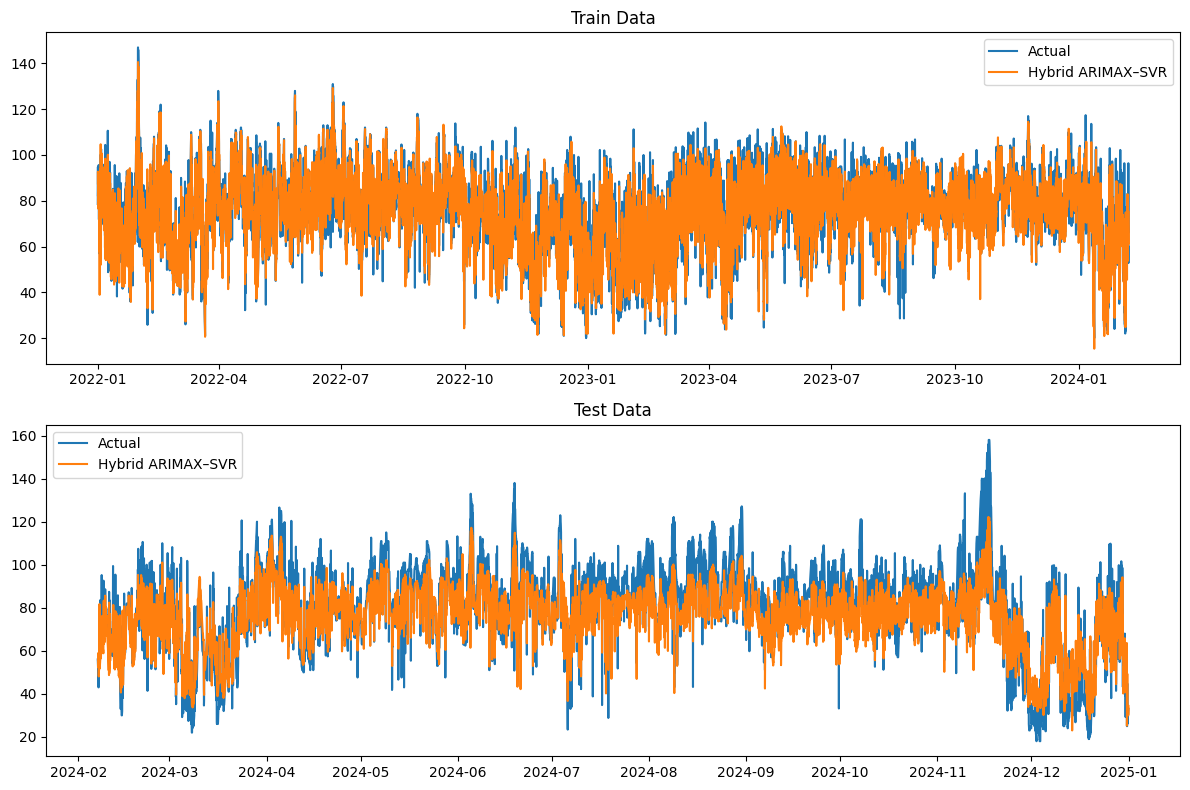

In [ ]:
import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
from scipy.stats import boxcox
from scipy.special import inv_boxcox
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# =====================================================
# 1. LOAD DATA
# =====================================================
df_path = "/content/drive/MyDrive/Data/Data Aqi Pollutant dan Meteorologi Kebon Jeruk.xlsx"
df = pd.read_excel(df_path, parse_dates=['datetime'], index_col='datetime')

y_raw = df['PM2.5']
X = df[['PM10','SO2','CO','O3','NO2',
        'Suhu Udara','Suhu Titik Embun','Curah Hujan',
        'Kelembaban Relatif','Kecepatan Angin']]

# =====================================================
# 2. BOX-COX TRANSFORMATION
# =====================================================
y_pos = y_raw + 1
y_boxcox, lmbda = boxcox(y_pos)
y_bc = pd.Series(y_boxcox, index=y_raw.index)

# =====================================================
# 3. TRAIN TEST SPLIT
# =====================================================
train_size = int(len(df) * 0.7)

y_train_bc = y_bc.iloc[:train_size]
y_test_bc  = y_bc.iloc[train_size:]

X_train = X.iloc[:train_size]
X_test  = X.iloc[train_size:]

y_train_real = y_raw.iloc[:train_size]
y_test_real  = y_raw.iloc[train_size:]

# =====================================================
# 4. ARIMAX MODEL
# =====================================================
order = (0, 1, 2)

model = SARIMAX(
    y_train_bc,
    exog=X_train,
    order=order,
    enforce_stationarity=False,
    enforce_invertibility=False
)

result = model.fit()
print(result.summary())

# =====================================================
# 5. PREDIKSI ARIMAX + INVERSE BOXCOX
# =====================================================
pred_train_bc = result.get_prediction(
    start=y_train_bc.index[0],
    end=y_train_bc.index[-1],
    exog=X_train
).predicted_mean

pred_test_bc = result.get_prediction(
    start=y_test_bc.index[0],
    end=y_test_bc.index[-1],
    exog=X_test
).predicted_mean

arimax_train = inv_boxcox(pred_train_bc, lmbda) - 1
arimax_test  = inv_boxcox(pred_test_bc,  lmbda) - 1

# =====================================================
# 6. HITUNG RESIDUAL ARIMAX
# =====================================================
residual_train = y_train_real - arimax_train
residual_test  = y_test_real  - arimax_test

# =====================================================
# 7. BUAT LAG RESIDUAL
# =====================================================
def create_lagged_residual(residual, n_lags=2):
    df_lag = pd.DataFrame({'residual': residual})
    for i in range(1, n_lags + 1):
        df_lag[f'lag{i}'] = df_lag['residual'].shift(i)
    return df_lag.dropna()

df_res_train = create_lagged_residual(residual_train, n_lags=2)
df_res_test  = create_lagged_residual(residual_test,  n_lags=2)

X_train_res = df_res_train[['lag1','lag2']]
y_train_res = df_res_train['residual']

X_test_res = df_res_test[['lag1','lag2']]
y_test_res = df_res_test['residual']

# =====================================================
# 8. SCALING DATA
# =====================================================
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_train_scaled = scaler_X.fit_transform(X_train_res)
X_test_scaled  = scaler_X.transform(X_test_res)

y_train_scaled = scaler_y.fit_transform(
    y_train_res.values.reshape(-1, 1)
).ravel()

# =====================================================
# 9. MODEL SVR (GRID SEARCH)
# =====================================================
param_grid = {
    'C': [10, 12, 14, 16, 18, 20],
    'gamma': [0.001, 0.004, 0.007, 0.01],
    'epsilon': [0.0001, 0.0004, 0.0007, 0.001]
}

svr = SVR(kernel='rbf')

grid_search = GridSearchCV(
    svr,
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train_scaled, y_train_scaled)
print("Best SVR Parameters:", grid_search.best_params_)

svr_best = grid_search.best_estimator_

# =====================================================
# 10. PREDIKSI RESIDUAL DENGAN SVR
# =====================================================
train_pred_res_scaled = svr_best.predict(X_train_scaled)
train_pred_res = scaler_y.inverse_transform(
    train_pred_res_scaled.reshape(-1, 1)
).ravel()

test_pred_res_scaled = svr_best.predict(X_test_scaled)
test_pred_res = scaler_y.inverse_transform(
    test_pred_res_scaled.reshape(-1, 1)
).ravel()

# =====================================================
# 11. HYBRID ARIMAX–SVR
# =====================================================
arimax_train_sync = arimax_train.iloc[-len(train_pred_res):].values
hybrid_train = arimax_train_sync + train_pred_res

arimax_test_sync = arimax_test.iloc[-len(test_pred_res):].values
hybrid_test = arimax_test_sync + test_pred_res

# =====================================================
# 12. EVALUASI MODEL
# =====================================================
print("\n=========== HYBRID TRAIN ===========")
print("MAE :", mean_absolute_error(
    y_train_real.iloc[-len(hybrid_train):], hybrid_train))
print("RMSE:", np.sqrt(mean_squared_error(
    y_train_real.iloc[-len(hybrid_train):], hybrid_train)))
print("R2  :", r2_score(
    y_train_real.iloc[-len(hybrid_train):], hybrid_train))

print("\n=========== HYBRID TEST ===========")
print("MAE :", mean_absolute_error(
    y_test_real.iloc[-len(hybrid_test):], hybrid_test))
print("RMSE:", np.sqrt(mean_squared_error(
    y_test_real.iloc[-len(hybrid_test):], hybrid_test)))
print("R2  :", r2_score(
    y_test_real.iloc[-len(hybrid_test):], hybrid_test))

# =====================================================
# 13. VISUALISASI
# =====================================================
fig, ax = plt.subplots(2, 1, figsize=(12, 8))

# Train
ax[0].plot(y_train_real.index, y_train_real, label='Actual')
ax[0].plot(
    y_train_real.index[-len(hybrid_train):],
    hybrid_train,
    label='Hybrid ARIMAX–SVR'
)
ax[0].set_title('Train Data')
ax[0].legend()

# Test
ax[1].plot(y_test_real.index, y_test_real, label='Actual')
ax[1].plot(
    y_test_real.index[-len(hybrid_test):],
    hybrid_test,
    label='Hybrid ARIMAX–SVR'
)
ax[1].set_title('Test Data')
ax[1].legend()

plt.tight_layout()
plt.show()

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                18412
Model:               SARIMAX(0, 1, 2)   Log Likelihood              -86578.993
Date:                Fri, 30 Jan 2026   AIC                         173183.986
Time:                        16:41:13   BIC                         173285.653
Sample:                    01-01-2022   HQIC                        173217.382
                         - 02-07-2024                                         
Covariance Type:                  opg                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
PM10                   2.7926      0.028    101.098      0.000       2.738       2.847
SO2                    0.1586      0.036      4.414      0.000       0.088       0.229
CO                  

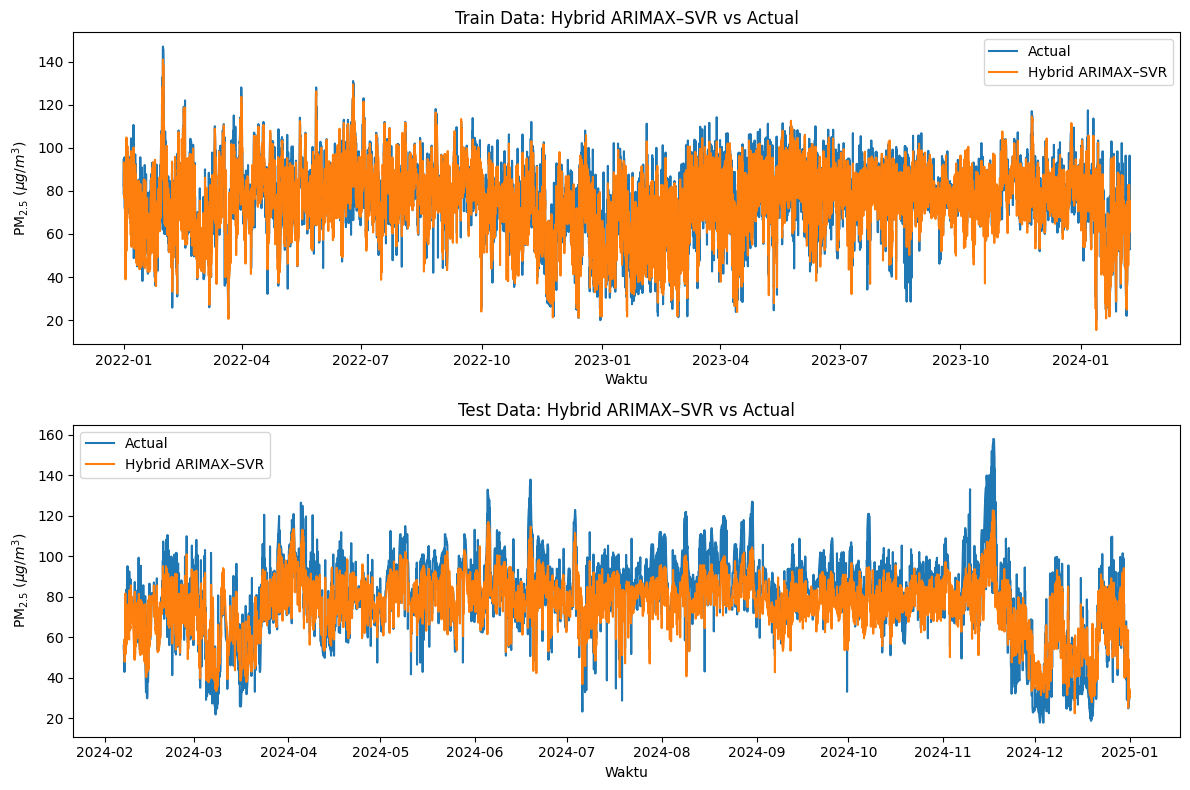

In [5]:
import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
from scipy.stats import boxcox
from scipy.special import inv_boxcox
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# =====================================================
# 1. LOAD DATA
# =====================================================
df_path = "/content/drive/MyDrive/Data/Data Aqi Pollutant dan Meteorologi Kebon Jeruk.xlsx"
df = pd.read_excel(df_path, parse_dates=['datetime'], index_col='datetime')

y_raw = df['PM2.5']
X = df[['PM10','SO2','CO','O3','NO2',
        'Suhu Udara','Suhu Titik Embun','Curah Hujan',
        'Kelembaban Relatif','Kecepatan Angin']]

# =====================================================
# 2. BOX-COX TRANSFORMATION
# =====================================================
y_pos = y_raw + 1
y_boxcox, lmbda = boxcox(y_pos)
y_bc = pd.Series(y_boxcox, index=y_raw.index)

# =====================================================
# 3. TRAIN TEST SPLIT
# =====================================================
train_size = int(len(df) * 0.7)

y_train_bc = y_bc.iloc[:train_size]
y_test_bc  = y_bc.iloc[train_size:]

X_train = X.iloc[:train_size]
X_test  = X.iloc[train_size:]

y_train_real = y_raw.iloc[:train_size]
y_test_real  = y_raw.iloc[train_size:]

# =====================================================
# 4. ARIMAX MODEL
# =====================================================
order = (0, 1, 2)

model = SARIMAX(
    y_train_bc,
    exog=X_train,
    order=order,
    enforce_stationarity=False,
    enforce_invertibility=False
)

result = model.fit()
print(result.summary())

# =====================================================
# 5. PREDIKSI ARIMAX + INVERSE BOXCOX
# =====================================================
pred_train_bc = result.get_prediction(
    start=y_train_bc.index[0],
    end=y_train_bc.index[-1],
    exog=X_train
).predicted_mean

pred_test_bc = result.get_prediction(
    start=y_test_bc.index[0],
    end=y_test_bc.index[-1],
    exog=X_test
).predicted_mean

arimax_train = inv_boxcox(pred_train_bc, lmbda) - 1
arimax_test  = inv_boxcox(pred_test_bc,  lmbda) - 1

# =====================================================
# 6. HITUNG RESIDUAL ARIMAX
# =====================================================
residual_train = y_train_real - arimax_train
residual_test  = y_test_real  - arimax_test

# =====================================================
# 7. BUAT LAG RESIDUAL
# =====================================================
def create_lagged_residual(residual, n_lags=3):
    df_lag = pd.DataFrame({'residual': residual})
    for i in range(1, n_lags + 1):
        df_lag[f'lag{i}'] = df_lag['residual'].shift(i)
    return df_lag.dropna()

df_res_train = create_lagged_residual(residual_train, n_lags=3)
df_res_test  = create_lagged_residual(residual_test,  n_lags=3)

X_train_res = df_res_train[['lag1', 'lag2', 'lag3']]
y_train_res = df_res_train['residual']

X_test_res = df_res_test[['lag1', 'lag2', 'lag3']]
y_test_res = df_res_test['residual']

# =====================================================
# 8. SCALING DATA
# =====================================================
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_train_scaled = scaler_X.fit_transform(X_train_res)
X_test_scaled  = scaler_X.transform(X_test_res)

y_train_scaled = scaler_y.fit_transform(
    y_train_res.values.reshape(-1, 1)
).ravel()

# =====================================================
# 9. MODEL SVR (GRID SEARCH)
# =====================================================
param_grid = {
    'C': [10, 12, 14, 16, 18, 20],
    'gamma': [0.001, 0.004, 0.007, 0.01],
    'epsilon': [0.0001, 0.0004, 0.0007, 0.001]
}

svr = SVR(kernel='rbf')

grid_search = GridSearchCV(
    svr,
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train_scaled, y_train_scaled)
print("Best SVR Parameters:", grid_search.best_params_)

svr_best = grid_search.best_estimator_

# =====================================================
# 10. PREDIKSI RESIDUAL DENGAN SVR
# =====================================================
train_pred_res_scaled = svr_best.predict(X_train_scaled)
train_pred_res = scaler_y.inverse_transform(
    train_pred_res_scaled.reshape(-1, 1)
).ravel()

test_pred_res_scaled = svr_best.predict(X_test_scaled)
test_pred_res = scaler_y.inverse_transform(
    test_pred_res_scaled.reshape(-1, 1)
).ravel()

# =====================================================
# 11. HYBRID ARIMAX–SVR
# =====================================================
arimax_train_sync = arimax_train.iloc[-len(train_pred_res):].values
hybrid_train = arimax_train_sync + train_pred_res

arimax_test_sync = arimax_test.iloc[-len(test_pred_res):].values
hybrid_test = arimax_test_sync + test_pred_res

# =====================================================
# 12. EVALUASI MODEL
# =====================================================
print("\n=========== HYBRID TRAIN ===========")
print("MAE :", mean_absolute_error(
    y_train_real.iloc[-len(hybrid_train):], hybrid_train))
print("RMSE:", np.sqrt(mean_squared_error(
    y_train_real.iloc[-len(hybrid_train):], hybrid_train)))
print("R2  :", r2_score(
    y_train_real.iloc[-len(hybrid_train):], hybrid_train))

print("\n=========== HYBRID TEST ===========")
print("MAE :", mean_absolute_error(
    y_test_real.iloc[-len(hybrid_test):], hybrid_test))
print("RMSE:", np.sqrt(mean_squared_error(
    y_test_real.iloc[-len(hybrid_test):], hybrid_test)))
print("R2  :", r2_score(
    y_test_real.iloc[-len(hybrid_test):], hybrid_test))

# =====================================================
# 13. VISUALISASI
# =====================================================
fig, ax = plt.subplots(2, 1, figsize=(12, 8))

# Train
ax[0].plot(y_train_real.index, y_train_real, label='Actual')
ax[0].plot(
    y_train_real.index[-len(hybrid_train):],
    hybrid_train,
    label='Hybrid ARIMAX–SVR'
)
ax[0].set_title('Train Data: Hybrid ARIMAX–SVR vs Actual')
ax[0].legend()

# Test
ax[1].plot(y_test_real.index, y_test_real, label='Actual')
ax[1].plot(
    y_test_real.index[-len(hybrid_test):],
    hybrid_test,
    label='Hybrid ARIMAX–SVR'
)
ax[1].set_title('Test Data: Hybrid ARIMAX–SVR vs Actual')
ax[1].legend()

ax[0].set_ylabel(r'PM$_{2.5}$ ($\mu g/m^3$)')
ax[1].set_ylabel(r'PM$_{2.5}$ ($\mu g/m^3$)')
ax[0].set_xlabel('Waktu')
ax[1].set_xlabel('Waktu')

plt.tight_layout()
plt.show()

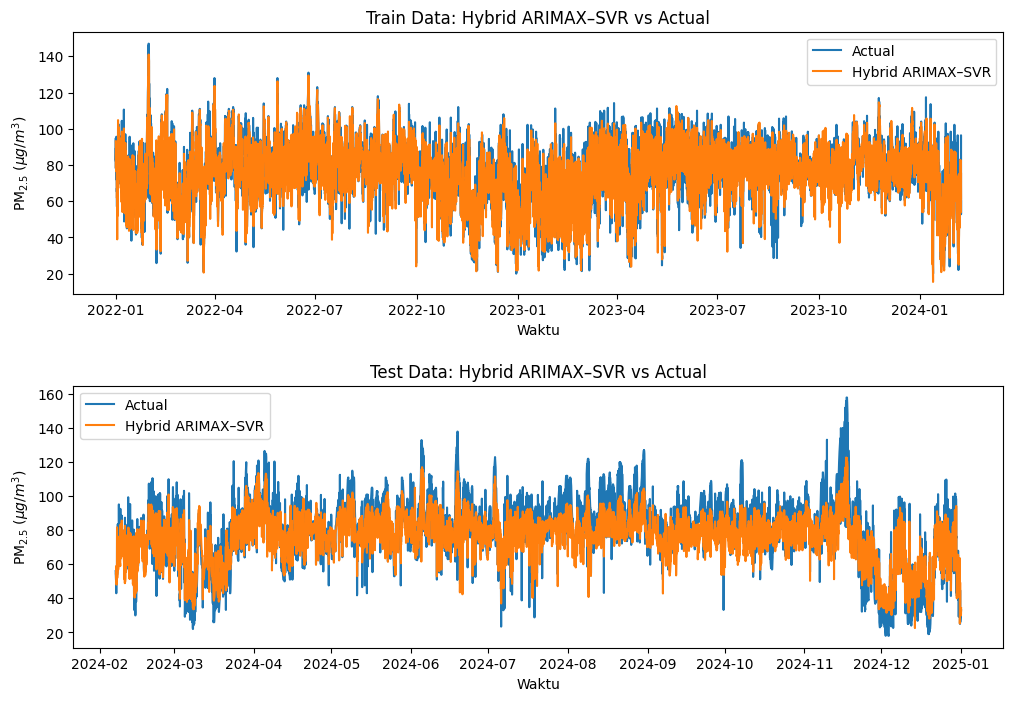

Gambar BERHASIL disimpan di:
/content/drive/MyDrive/Model ARIMAX 2/Kebun Jeruk/Gambar/Hybrid_Train_Test.jpeg


In [6]:
import os
# =========================
# 6. Plot + SIMPAN + TAMPIL
# =========================
output_dir = "/content/drive/MyDrive/Model ARIMAX 2/Kebun Jeruk/Gambar"
os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(output_dir, "Hybrid_Train_Test.jpeg")

fig, ax = plt.subplots(2, 1, figsize=(12, 8))

# Train
ax[0].plot(y_train_real.index, y_train_real, label='Actual')
ax[0].plot(
    y_train_real.index[-len(hybrid_train):],
    hybrid_train,
    label='Hybrid ARIMAX–SVR'
)
ax[0].set_title('Train Data: Hybrid ARIMAX–SVR vs Actual')
ax[0].legend()

# Test
ax[1].plot(y_test_real.index, y_test_real, label='Actual')
ax[1].plot(
    y_test_real.index[-len(hybrid_test):],
    hybrid_test,
    label='Hybrid ARIMAX–SVR'
)
ax[1].set_title('Test Data: Hybrid ARIMAX–SVR vs Actual')
ax[1].legend()

ax[0].set_ylabel(r'PM$_{2.5}$ ($\mu g/m^3$)')
ax[1].set_ylabel(r'PM$_{2.5}$ ($\mu g/m^3$)')
ax[0].set_xlabel('Waktu')
ax[1].set_xlabel('Waktu')

plt.subplots_adjust(hspace=0.35)
plt.savefig(output_path, dpi=600, bbox_inches="tight")
plt.show()
plt.close()

print("Gambar BERHASIL disimpan di:")
print(output_path)

SVR

Fitting 5 folds for each of 64 candidates, totalling 320 fits

================ BEST PARAMETER ================
{'C': 1, 'epsilon': 0.0004, 'gamma': 0.001}

================ PERFORMANCE RESULT ================

       Station  Train RMSE  Train MAE  Train R2  Test RMSE  Test MAE   Test R2
0  Kebun Jeruk    8.620511   6.575756  0.741275  13.716937  10.35365  0.584724


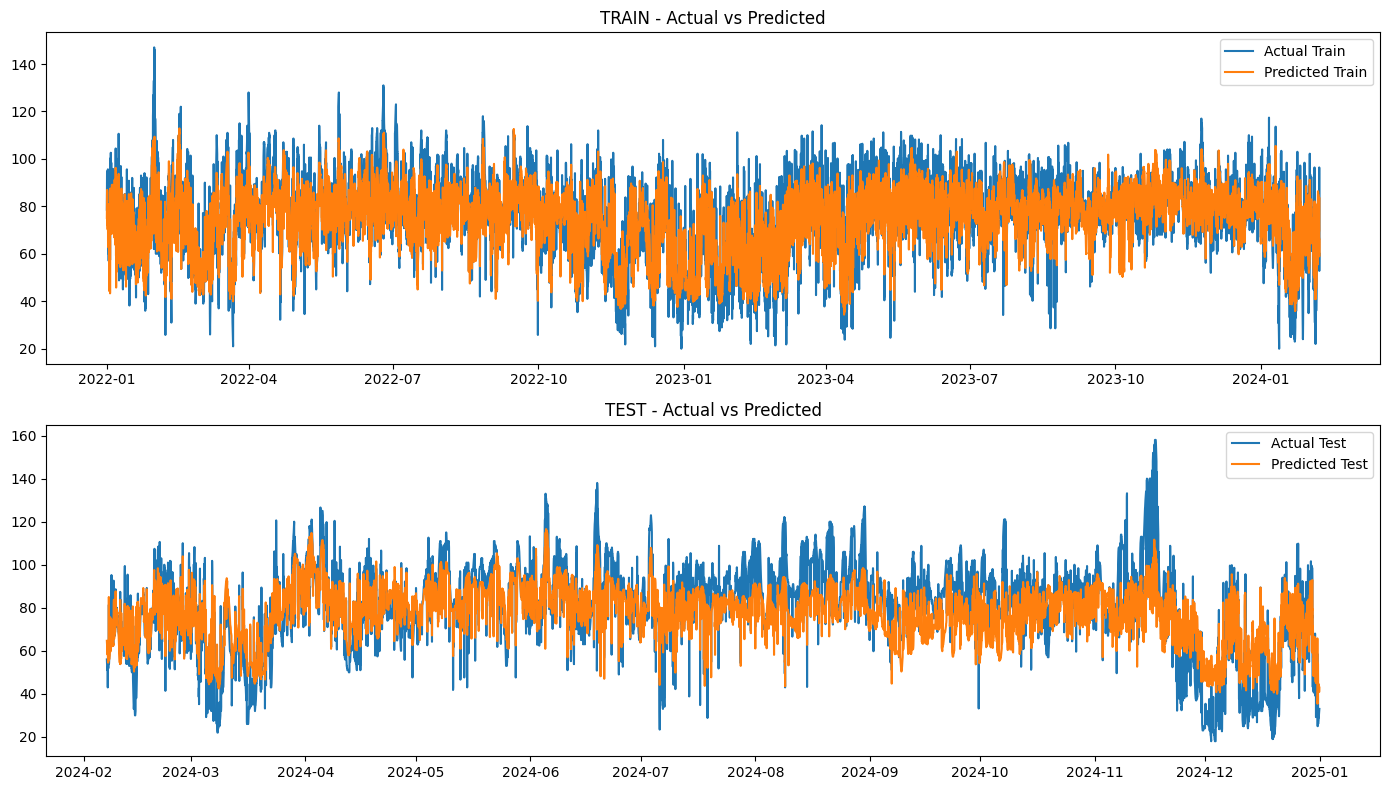


============ FEATURE IMPORTANCE ============

              Feature  Importance Mean  Importance Std
5                PM10         0.441398        0.006924
9                 NO2         0.065743        0.001613
7                  CO         0.064374        0.001439
8                  O3         0.027304        0.000692
4     Kecepatan Angin         0.019025        0.000801
1    Suhu Titik Embun         0.005238        0.000184
3  Kelembaban Relatif         0.004097        0.000180
6                 SO2         0.002330        0.000078
0          Suhu Udara         0.002013        0.000156
2         Curah Hujan         0.001286        0.000105


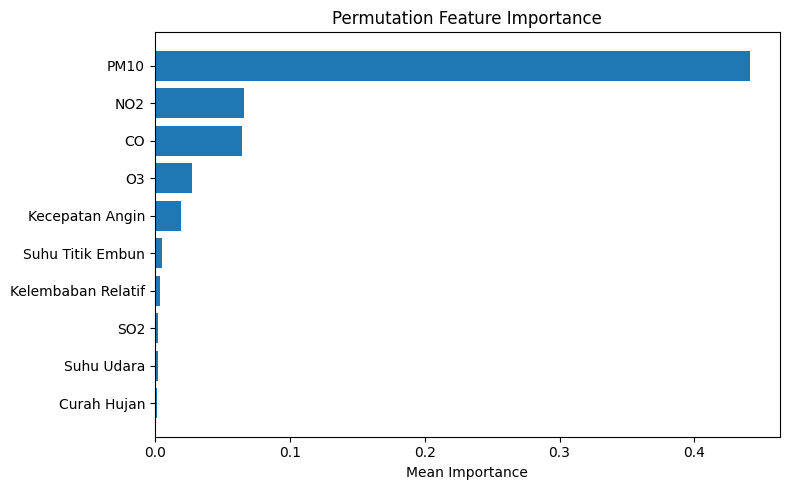

In [ ]:
# ===============================
# IMPORT LIBRARY
# ===============================
import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt

from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

# ===============================
# LOAD DATA
# ===============================
df_path = "/content/drive/MyDrive/Data/Data Aqi Pollutant dan Meteorologi Kebon Jeruk.xlsx"
df = pd.read_excel(df_path)

# ===============================
# DEFINISI KOLOM
# ===============================
target_col = 'PM2.5'

meteorology_cols = ['Suhu Udara','Suhu Titik Embun','Curah Hujan','Kelembaban Relatif','Kecepatan Angin']
pollutant_cols = ['PM10','SO2','CO','O3','NO2']

feature_cols = meteorology_cols + pollutant_cols

# ===============================
# PREPROCESSING
# ===============================
df = df.dropna().reset_index(drop=True)

# ===============================
# TRAIN - TEST SPLIT
# ===============================
split_index = int(len(df) * 0.7)

train_df = df.iloc[:split_index].copy()
test_df  = df.iloc[split_index:].copy()

X_train = train_df[feature_cols]
y_train = train_df[target_col]

X_test = test_df[feature_cols]
y_test = test_df[target_col]

datetime_train = train_df['datetime']
datetime_test  = test_df['datetime']

# ===============================
# SCALING DATA
# ===============================
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled  = scaler_X.transform(X_test)

y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1,1)).ravel()
y_test_scaled  = scaler_y.transform(y_test.values.reshape(-1,1)).ravel()

# ===============================
# HYPERPARAMETER TUNING SVR
# ===============================
tscv = TimeSeriesSplit(n_splits=5)

param_grid = {
    'C': [1, 4, 7, 10],
    'gamma': [0.001, 0.004, 0.007, 0.01],
    'epsilon': [0.0001, 0.0004, 0.0007, 0.001]
}

grid = GridSearchCV(
    SVR(kernel='rbf'),
    param_grid,
    cv=tscv,
    scoring='r2',
    n_jobs=-1,
    verbose=2
)

grid.fit(X_train_scaled, y_train_scaled)

print("\n================ BEST PARAMETER ================")
print(grid.best_params_)

svr = grid.best_estimator_

# ===============================
# PREDIKSI MODEL
# ===============================
y_train_pred_scaled = svr.predict(X_train_scaled)
y_test_pred_scaled  = svr.predict(X_test_scaled)

# Inverse scaling
y_train_pred = scaler_y.inverse_transform(y_train_pred_scaled.reshape(-1,1))
y_test_pred  = scaler_y.inverse_transform(y_test_pred_scaled.reshape( -1,1))

y_train_actual = y_train.values.reshape(-1,1)
y_test_actual  = y_test.values.reshape(-1,1)

# ===============================
# EVALUASI AKURASI
# ===============================
train_rmse = math.sqrt(mean_squared_error(y_train_actual, y_train_pred))
train_mae  = mean_absolute_error(y_train_actual, y_train_pred)
train_r2   = r2_score(y_train_actual, y_train_pred)

test_rmse = math.sqrt(mean_squared_error(y_test_actual, y_test_pred))
test_mae  = mean_absolute_error(y_test_actual, y_test_pred)
test_r2   = r2_score(y_test_actual, y_test_pred)

results_df = pd.DataFrame([{
    'Station': 'Kebun Jeruk',
    'Train RMSE': train_rmse,
    'Train MAE': train_mae,
    'Train R2': train_r2,
    'Test RMSE': test_rmse,
    'Test MAE': test_mae,
    'Test R2': test_r2
}])

print("\n================ PERFORMANCE RESULT ================\n")
print(results_df)

# ===============================
# VISUALISASI ACTUAL VS PREDIKSI
# ===============================
plt.style.use('default')
fig, ax = plt.subplots(2, 1, figsize=(14,8), sharex=False)

# TRAIN
ax[0].plot(datetime_train, y_train_actual, label="Actual Train")
ax[0].plot(datetime_train, y_train_pred, label="Predicted Train")
ax[0].set_title("TRAIN - Actual vs Predicted")
ax[0].legend()

# TEST
ax[1].plot(datetime_test, y_test_actual, label="Actual Test")
ax[1].plot(datetime_test, y_test_pred, label="Predicted Test")
ax[1].set_title("TEST - Actual vs Predicted")
ax[1].legend()

plt.tight_layout()
plt.show()

# ===============================
# PERMUTATION FEATURE IMPORTANCE
# ===============================
importance = permutation_importance(
    svr, X_test_scaled, y_test_scaled,
    n_repeats=30, random_state=42, scoring='r2'
)

importance_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance Mean': importance.importances_mean,
    'Importance Std' : importance.importances_std
}).sort_values(by='Importance Mean', ascending=False)

print("\n============ FEATURE IMPORTANCE ============\n")
print(importance_df)

# Plot
plt.figure(figsize=(8,5))
plt.barh(importance_df['Feature'], importance_df['Importance Mean'])
plt.gca().invert_yaxis()
plt.title("Permutation Feature Importance")
plt.xlabel("Mean Importance")
plt.tight_layout()
plt.show()

Fitting 5 folds for each of 96 candidates, totalling 480 fits

================ BEST PARAMETER ================
{'C': 20, 'epsilon': 0.001, 'gamma': 0.01}

================ PERFORMANCE RESULT ================

       Station  Train RMSE  Train MAE  Train R2  Test RMSE  Test MAE   Test R2
0  Kebun Jeruk    7.939426   5.972645  0.780542  12.619003  9.419549  0.648543


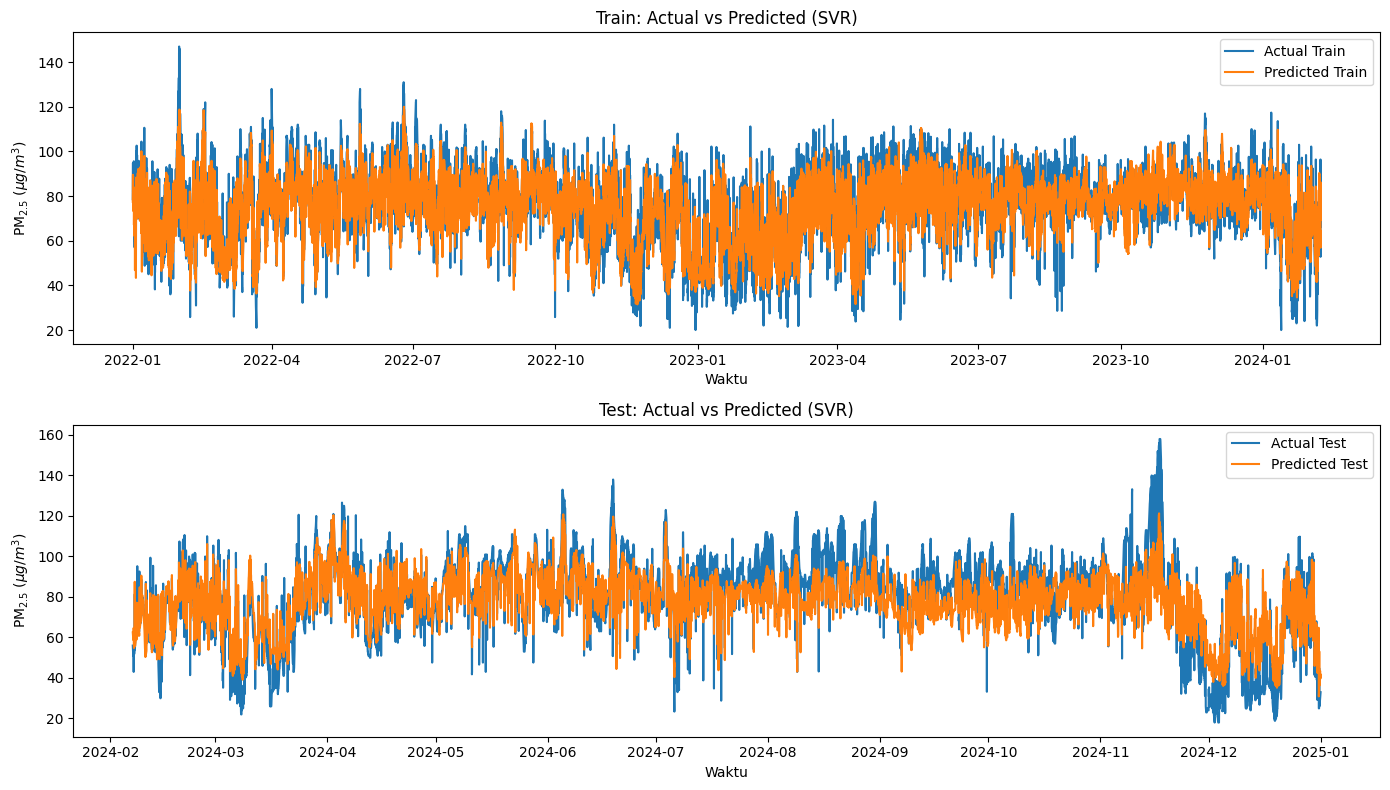


============ FEATURE IMPORTANCE ============

              Feature  Importance Mean  Importance Std
5                PM10         0.462366        0.006533
7                  CO         0.096794        0.001980
9                 NO2         0.048806        0.001056
8                  O3         0.029162        0.000621
4     Kecepatan Angin         0.026770        0.000856
1    Suhu Titik Embun         0.017126        0.001020
3  Kelembaban Relatif         0.011997        0.000743
6                 SO2         0.004536        0.000192
0          Suhu Udara         0.002520        0.000503
2         Curah Hujan         0.002436        0.000224


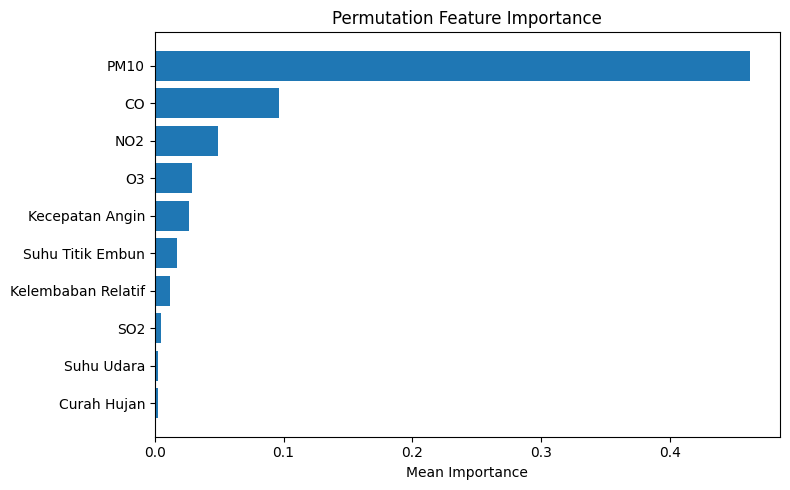

In [7]:
# ===============================
# IMPORT LIBRARY
# ===============================
import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt

from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

# ===============================
# LOAD DATA
# ===============================
df_path = "/content/drive/MyDrive/Data/Data Aqi Pollutant dan Meteorologi Kebon Jeruk.xlsx"
df = pd.read_excel(df_path)

# ===============================
# DEFINISI KOLOM
# ===============================
target_col = 'PM2.5'

meteorology_cols = ['Suhu Udara','Suhu Titik Embun','Curah Hujan','Kelembaban Relatif','Kecepatan Angin']
pollutant_cols = ['PM10','SO2','CO','O3','NO2']

feature_cols = meteorology_cols + pollutant_cols

# ===============================
# PREPROCESSING
# ===============================
df = df.dropna().reset_index(drop=True)

# ===============================
# TRAIN - TEST SPLIT
# ===============================
split_index = int(len(df) * 0.7)

train_df = df.iloc[:split_index].copy()
test_df  = df.iloc[split_index:].copy()

X_train = train_df[feature_cols]
y_train = train_df[target_col]

X_test = test_df[feature_cols]
y_test = test_df[target_col]

datetime_train = train_df['datetime']
datetime_test  = test_df['datetime']

# ===============================
# SCALING DATA
# ===============================
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled  = scaler_X.transform(X_test)

y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1,1)).ravel()
y_test_scaled  = scaler_y.transform(y_test.values.reshape(-1,1)).ravel()

# ===============================
# HYPERPARAMETER TUNING SVR
# ===============================
tscv = TimeSeriesSplit(n_splits=5)

param_grid = {
    'C': [10, 12, 14, 16, 18, 20],
    'gamma': [0.001, 0.004, 0.007, 0.01],
    'epsilon': [0.0001, 0.0004, 0.0007, 0.001]
}

grid = GridSearchCV(
    SVR(kernel='rbf'),
    param_grid,
    cv=tscv,
    scoring='r2',
    n_jobs=-1,
    verbose=2
)

grid.fit(X_train_scaled, y_train_scaled)

print("\n================ BEST PARAMETER ================")
print(grid.best_params_)

svr = grid.best_estimator_

# ===============================
# PREDIKSI MODEL
# ===============================
y_train_pred_scaled = svr.predict(X_train_scaled)
y_test_pred_scaled  = svr.predict(X_test_scaled)

# Inverse scaling
y_train_pred = scaler_y.inverse_transform(y_train_pred_scaled.reshape(-1,1))
y_test_pred  = scaler_y.inverse_transform(y_test_pred_scaled.reshape( -1,1))

y_train_actual = y_train.values.reshape(-1,1)
y_test_actual  = y_test.values.reshape(-1,1)

# ===============================
# EVALUASI AKURASI
# ===============================
train_rmse = math.sqrt(mean_squared_error(y_train_actual, y_train_pred))
train_mae  = mean_absolute_error(y_train_actual, y_train_pred)
train_r2   = r2_score(y_train_actual, y_train_pred)

test_rmse = math.sqrt(mean_squared_error(y_test_actual, y_test_pred))
test_mae  = mean_absolute_error(y_test_actual, y_test_pred)
test_r2   = r2_score(y_test_actual, y_test_pred)

results_df = pd.DataFrame([{
    'Station': 'Kebun Jeruk',
    'Train RMSE': train_rmse,
    'Train MAE': train_mae,
    'Train R2': train_r2,
    'Test RMSE': test_rmse,
    'Test MAE': test_mae,
    'Test R2': test_r2
}])

print("\n================ PERFORMANCE RESULT ================\n")
print(results_df)

# ===============================
# VISUALISASI ACTUAL VS PREDIKSI
# ===============================
plt.style.use('default')
fig, ax = plt.subplots(2, 1, figsize=(14,8), sharex=False)

# TRAIN
ax[0].plot(datetime_train, y_train_actual, label="Actual Train")
ax[0].plot(datetime_train, y_train_pred, label="Predicted Train")
ax[0].set_title('Train: Actual vs Predicted (SVR)', fontsize=12)
ax[0].legend()

# TEST
ax[1].plot(datetime_test, y_test_actual, label="Actual Test")
ax[1].plot(datetime_test, y_test_pred, label="Predicted Test")
ax[1].set_title('Test: Actual vs Predicted (SVR)', fontsize=12)
ax[1].legend()

ax[0].set_ylabel(r'PM$_{2.5}$ ($\mu g/m^3$)')
ax[1].set_ylabel(r'PM$_{2.5}$ ($\mu g/m^3$)')
ax[0].set_xlabel('Waktu')
ax[1].set_xlabel('Waktu')

plt.tight_layout()
plt.show()

# ===============================
# PERMUTATION FEATURE IMPORTANCE
# ===============================
importance = permutation_importance(
    svr, X_test_scaled, y_test_scaled,
    n_repeats=30, random_state=42, scoring='r2'
)

importance_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance Mean': importance.importances_mean,
    'Importance Std' : importance.importances_std
}).sort_values(by='Importance Mean', ascending=False)

print("\n============ FEATURE IMPORTANCE ============\n")
print(importance_df)

# Plot
plt.figure(figsize=(8,5))
plt.barh(importance_df['Feature'], importance_df['Importance Mean'])
plt.gca().invert_yaxis()
plt.title("Permutation Feature Importance")
plt.xlabel("Mean Importance")
plt.tight_layout()
plt.show()

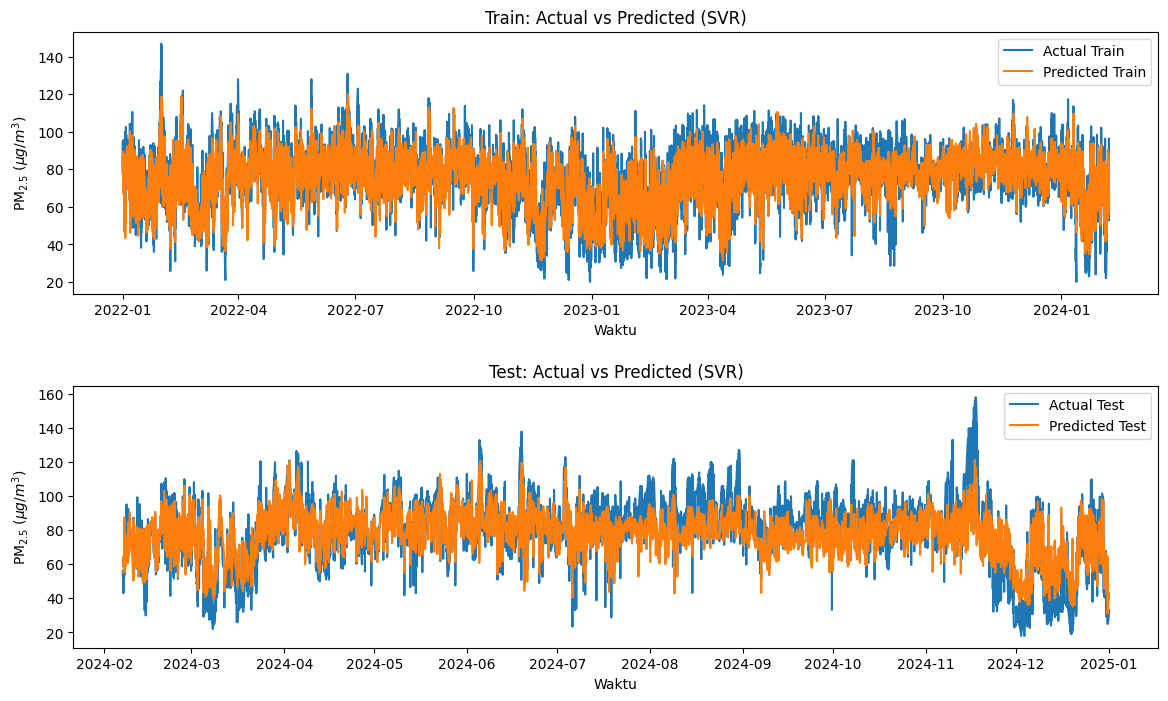

Gambar BERHASIL disimpan di:
/content/drive/MyDrive/Model ARIMAX 2/Kebun Jeruk/Gambar/SVR_Train_Test.jpeg


In [8]:
import os
# =========================
# 6. Plot + SIMPAN + TAMPIL
# =========================
output_dir = "/content/drive/MyDrive/Model ARIMAX 2/Kebun Jeruk/Gambar"
os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(output_dir, "SVR_Train_Test.jpeg")

plt.style.use('default')
fig, ax = plt.subplots(2, 1, figsize=(14,8), sharex=False)

# TRAIN
ax[0].plot(datetime_train, y_train_actual, label="Actual Train")
ax[0].plot(datetime_train, y_train_pred, label="Predicted Train")
ax[0].set_title('Train: Actual vs Predicted (SVR)', fontsize=12)
ax[0].legend()

# TEST
ax[1].plot(datetime_test, y_test_actual, label="Actual Test")
ax[1].plot(datetime_test, y_test_pred, label="Predicted Test")
ax[1].set_title('Test: Actual vs Predicted (SVR)', fontsize=12)
ax[1].legend()

ax[0].set_ylabel(r'PM$_{2.5}$ ($\mu g/m^3$)')
ax[1].set_ylabel(r'PM$_{2.5}$ ($\mu g/m^3$)')
ax[0].set_xlabel('Waktu')
ax[1].set_xlabel('Waktu')

plt.subplots_adjust(hspace=0.35)
plt.savefig(output_path, dpi=600, bbox_inches="tight")
plt.show()
plt.close()

print("Gambar BERHASIL disimpan di:")
print(output_path)